# Engineering Mathematics - Computer Assignment 1
## Audio Engineering, Musical Instruments, and Signal Processing with Fourier Series

- **School of Electrical and Computer Engineering - College of Engineering, University of Tehran**
- **Course:** Engineering Mathematics
- **Student Name:** Parmis Roshankar
- **Student ID:** 810103439

---

### General Instructions:
1. This assignment consists of **3 Main Sections** and an **Optional Bonus Section**.
2. Complete all implementation cells marked with `# Your code here`.
3. Provide your analytical explanations and answers in the designated Markdown cells under each section.
4. Ensure all cells execute sequentially from top to bottom (`Kernel -> Restart & Run All`) before submitting.
5. The required audio files (`mystery_melody.wav` and `noisy_music.wav`) are located in the `audio_assets/` directory.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import wave
import os

# Configure plot styling
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 10


---
## Section 1: Harmonic Synthesis and Timbre Analysis of 4 Instruments

In acoustics, every musical note with fundamental frequency $f_0$ consists of a periodic superposition of sinusoidal harmonics. In basic additive sound synthesis, we model the acoustic wave using harmonic sine terms:
$$s(t) = \sum_{n=1}^N A_n \sin(2\pi n f_0 t)$$

In this section, analyze four distinct instruments playing the musical note **A4 ($f_0 = 440\text{ Hz}$)**:
1. **Flute:** Dominated by the fundamental harmonic:
   $$A_1 = 1.0, \quad A_2 = 0.15, \quad A_3 = 0.04$$
2. **Clarinet:** Cylindrical pipe with one closed end; predominantly odd harmonics:
   $$A_1 = 1.0, \quad A_3 = 0.60, \quad A_5 = 0.35, \quad A_7 = 0.15$$
3. **Violin:** Stick-slip motion of bowed strings; full harmonic series decaying as $1/n$:
   $$A_n = \frac{1}{n} \quad (n = 1, 2, \dots, 8)$$
4. **Piano:** Hammer strike on vibrating strings with soundboard resonance; rich harmonic series with a percussive exponential decay envelope ($e^{-3.5 t / T}$):
   $$A = [1.0, 0.65, 0.40, 0.25, 0.15, 0.08, 0.04]$$

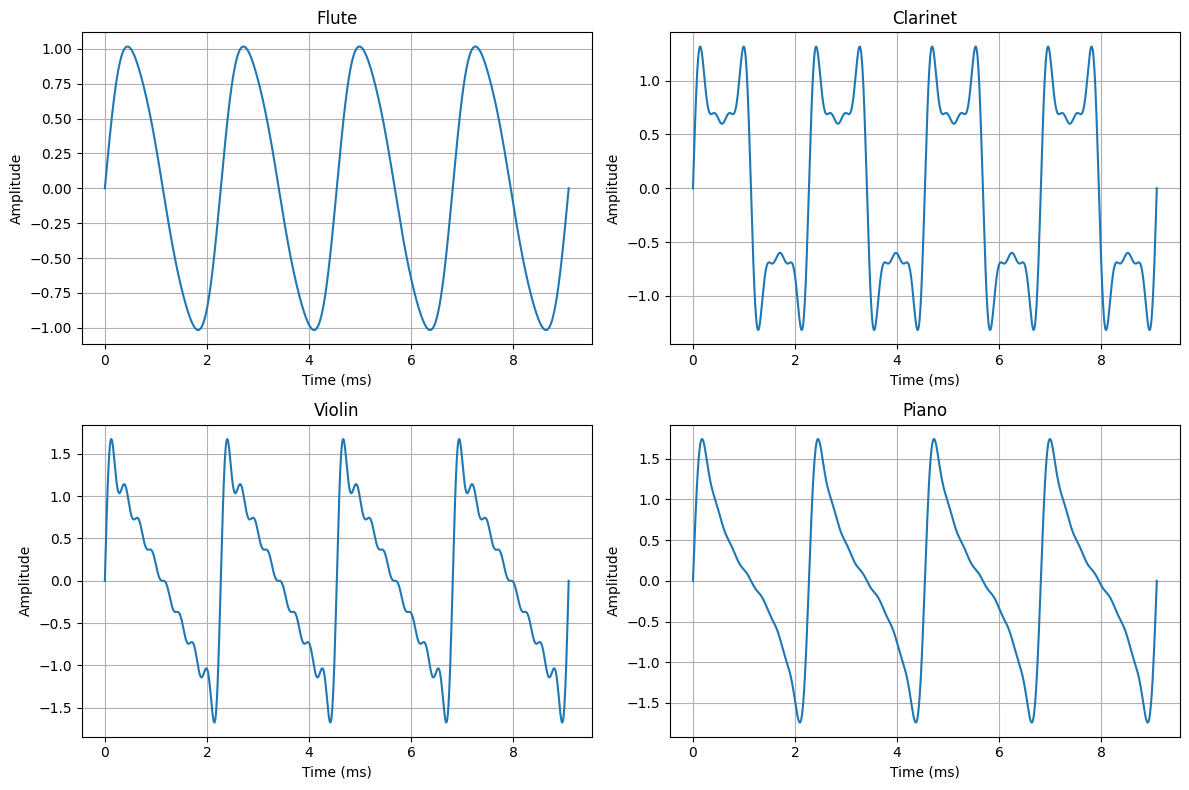

In [4]:
# 1. Synthesize and plot single-period waveforms for all 4 instruments (A4: 440 Hz)

f_0 = 440
T = 1 / f_0

flute = [(1, 1.0), (2, 0.15), (3, 0.04)]

clarinet = [(1, 1.0), (3, 0.6), (5, 0.35), (7, 0.15)]

violin = [(n, 1/n) for n in range(1, 9)]

piano = [(1, 1.0), (2, 0.65), (3, 0.40), (4, 0.25), (5, 0.15), (6, 0.08), (7, 0.04)]

instruments = [flute, clarinet, violin, piano]
names = ["Flute", "Clarinet", "Violin", "Piano"]

t = np.linspace(0, 4*T, 1000)

plt.figure(figsize=(12, 8))

for i in range(4) :

    s = np.zeros(len(t))
    for n, A in instruments[i]:
        s += A * np.sin(2 * np.pi * n * f_0 * t)

    plt.subplot(2, 2, i+1)
    plt.plot(t * 1000, s)
    plt.title(names[i])
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude")
    plt.grid()

plt.tight_layout()
plt.show()

Flute
Total Power: 0.51205
Fundamental Power Percentage: 97.64671418806758
--------------------
Clarinet
Total Power: 0.7525
Fundamental Power Percentage: 66.44518272425249
--------------------
Violin
Total Power: 0.7637110260770975
Fundamental Power Percentage: 65.46978934798362
--------------------
Piano
Total Power: 0.83775
Fundamental Power Percentage: 59.68367651447329
--------------------


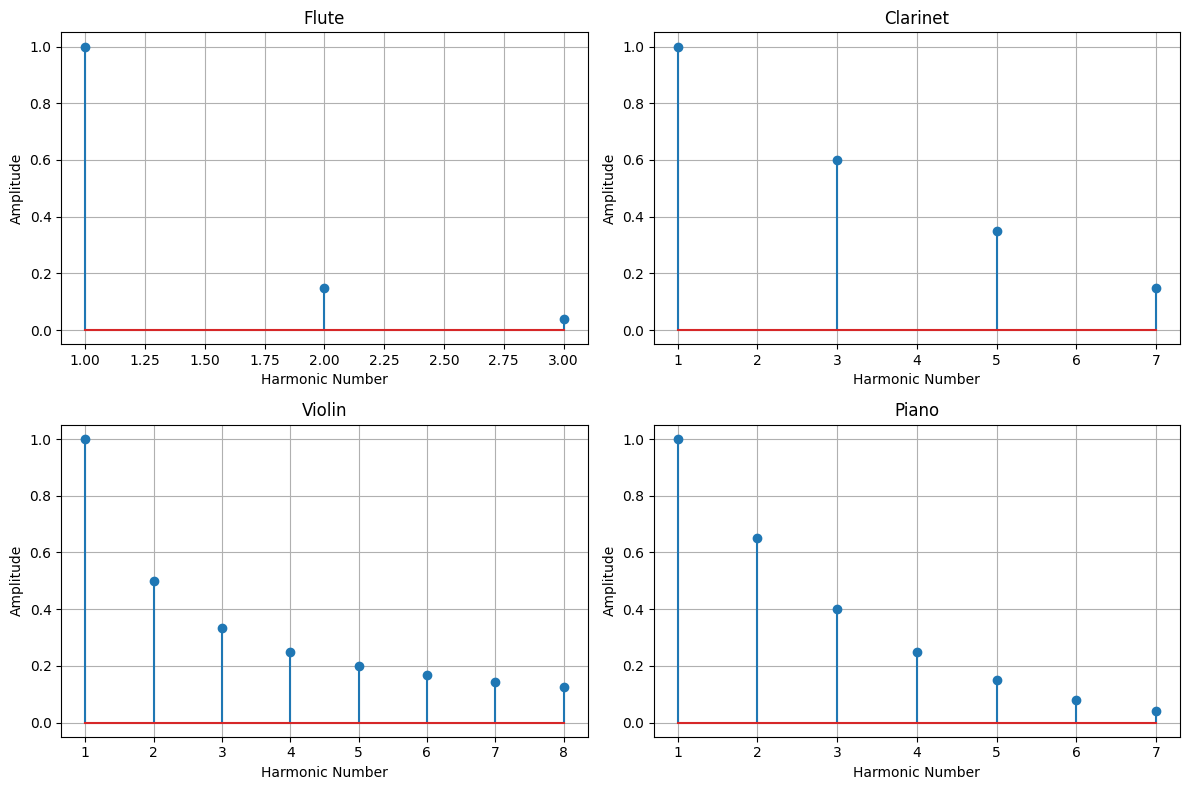

In [5]:
# 2. Calculate percentage of total power in the fundamental harmonic and plot stem spectra

plt.figure(figsize=(12, 8))
for i in range(4) :
    harmonics = instruments[i]
    total_power = 0
    for n, A in harmonics :
        total_power += A**2

    total_power = 0.5 * total_power
    fundamental_power = 0.5 * harmonics[0][1]**2
    percentage = (fundamental_power / total_power) * 100
    print(names[i])
    print("Total Power:", total_power)
    print("Fundamental Power Percentage:", percentage)
    print("--------------------")
    n_values = [n for n, A in harmonics]
    A_values = [A for n, A in harmonics]
    plt.subplot(2, 2, i+1)
    plt.stem(n_values, A_values)
    plt.title(names[i])
    plt.xlabel("Harmonic Number")
    plt.ylabel("Amplitude")
    plt.grid()

plt.tight_layout()
plt.show()

In [6]:
# 3. Synthesize 1.5-second audio signals for note A4 (440 Hz) and export as WAV files

f_s = 44100
duration = 1.5
t = np.arange(int(f_s * duration)) / f_s
for i in range(4) :
    s = np.zeros(len(t))
    for n, A in instruments[i] :
        s += A * np.sin(2 * np.pi * n * f_0 * t)

    s = s / np.max(np.abs(s))
    audio = (s * 32767).astype(np.int16)
    filename = names[i] + ".wav"
    with wave.open(filename, "wb") as file:
        file.setnchannels(1)
        file.setsampwidth(2)
        file.setframerate(f_s)
        file.writeframes(audio.tobytes())
    print(filename, "saved")

Flute.wav saved
Clarinet.wav saved
Violin.wav saved
Piano.wav saved


**Flute**: Most of its signal power is concentrated in the fundamental harmonic, resulting in a simpler and purer sound.

**Clarinet**: It contains odd harmonics while even harmonics are absent, producing a different waveform and timbre.

**Violin**: It contains more harmonics, whose amplitudes gradually decrease.

**Piano**: It contains several harmonics with decreasing amplitudes, and higher harmonics still have a noticeable contribution in this model.

### Discussion & Analysis for Section 1:
Please answer the following analytical questions clearly and concisely:
1. **DC Component ($a_0$):** Why is the DC component ($a_0$) always zero in physical sound signals and audible perception? What happens mechanically if a signal with $a_0 \neq 0$ is sent to a speaker cone?
2. **Symmetry and Origin Choice:** In the synthesis equation $s(t) = \sum A_n \sin(2\pi n f_0 t)$, why are cosine coefficients ($a_n$) absent? Based on Fourier series parity/symmetry properties, what assumption about time symmetry and origin ($t=0$) does this correspond to?
3. **Ohm's Acoustic Law:** If we add arbitrary initial phase shifts $\phi_n$ to each harmonic (i.e. $s(t) = \sum A_n \sin(2\pi n f_0 t + \phi_n)$), the time-domain waveform changes drastically. Does the human ear perceive a noticeable change in instrument timbre? Explain based on auditory perception.
4. **Timbre and Harmonic Distribution:** Why does the flute sound soft and pure, whereas the violin sounds bright and piercing? How does the percentage of fundamental power relate to perceived timbre?

#### **Answers:**

> **1. DC Component ($a_0$):**
The DC component is a constant offset in a signal. In sound waves, pressure fluctuates around atmospheric pressure, so its average value is zero. If \(a_0 \neq 0\), it causes a constant force on the speaker cone, pushing it away from its resting position. This can cause distortion, overheating, or damage to the speaker. Therefore, DC does not produce audible sound and is usually removed from audio signals.

> **2.Symmetry and Origin Choice:**
In the Fourier synthesis equation, cosine terms are absent because the signal is assumed to have odd symmetry around \(t=0\). For an odd periodic signal, all cosine coefficients and the DC component are zero, leaving only sine terms in its Fourier series. This assumption corresponds to choosing the time origin at a point where the signal has odd symmetry. It is a mathematical simplification and is not necessarily true for every real musical sound.

> **3.Ohm's Acoustic Law:**
Adding arbitrary phase shifts changes the time-domain waveform significantly, but for steady-state musical tones, the human ear is generally less sensitive to the absolute phases of individual harmonics than to their frequencies and amplitudes. According to Ohm's acoustic law, the ear analyzes a complex sound into its frequency components. Therefore, if the harmonic frequencies and amplitudes remain unchanged, changing their phases usually does not produce a noticeable change in perceived timbre. However, phase relationships can affect the waveform and may influence perception, especially in transient sounds such as the beginning of a musical note.

> **4. Timbre and Harmonic Distribution:**
The flute sounds soft and pure because most of its signal power is concentrated in the fundamental harmonic, while its higher harmonics have much smaller amplitudes. In contrast, the violin has stronger contributions from higher harmonics, producing a richer and brighter sound. The percentage of fundamental power indicates how much of the total signal power is concentrated in the fundamental frequency. A higher percentage generally corresponds to a purer sound, while a lower percentage indicates a greater contribution from higher harmonics. However, timbre depends on the overall harmonic distribution, not only on the fundamental power percentage.

---
## Section 2: Music Detective: Instrument Recognition and Automated Note Detection

In this section, you will decode the mystery audio recording: `audio_assets/mystery_melody.wav`.  
Your goal is to identify the instrument played and extract the sequence of musical notes (pitch detection) using the Fourier series.

### Piano Note Reference Frequencies (Octave 4):
| Note | C4 (Do) | D4 (Re) | E4 (Mi) | F4 (Fa) | G4 (Sol) | A4 (La) | B4 (Si) | C5 (High Do) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| Frequency (Hz) | 261.63 | 293.66 | 329.63 | 349.23 | 392.00 | 440.00 | 493.88 | 523.25 |

Sample Rate: 44100 Hz
Duration: 8.0 seconds
Number of Samples: 352800


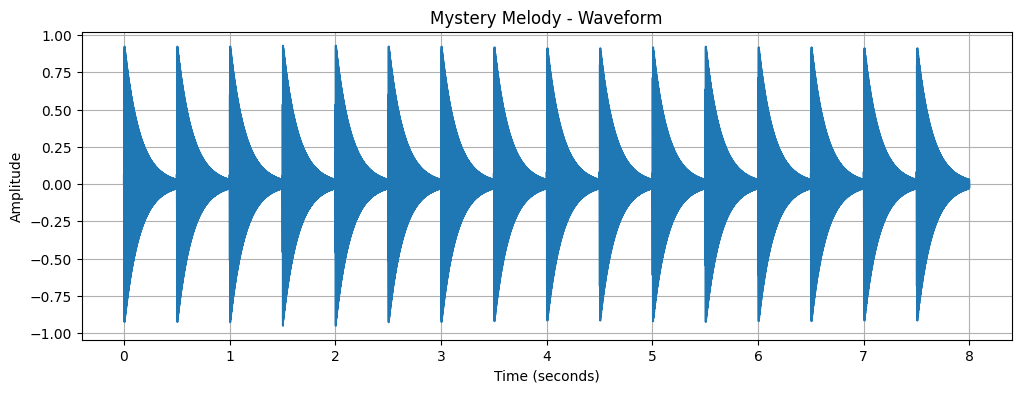

In [7]:
# 1. Load mystery_melody.wav and inspect its waveform

with wave.open("audio_assets/mystery_melody.wav", "rb") as audio_file :

    sample_rate = audio_file.getframerate()
    number_of_frames = audio_file.getnframes()
    channels = audio_file.getnchannels()
    audio_data = audio_file.readframes(number_of_frames)

audio_data = np.frombuffer(audio_data, dtype=np.int16)
if channels > 1 :
    audio_data = audio_data.reshape(-1, channels).mean(axis=1)

audio_data = audio_data / 32768
duration = len(audio_data) / sample_rate
print("Sample Rate:", sample_rate, "Hz")
print("Duration:", duration, "seconds")
print("Number of Samples:", len(audio_data))
time = np.arange(len(audio_data)) / sample_rate
plt.figure(figsize=(12, 4))
plt.plot(time, audio_data)
plt.title("Mystery Melody - Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

Fundamental Frequency: 329.73 Hz


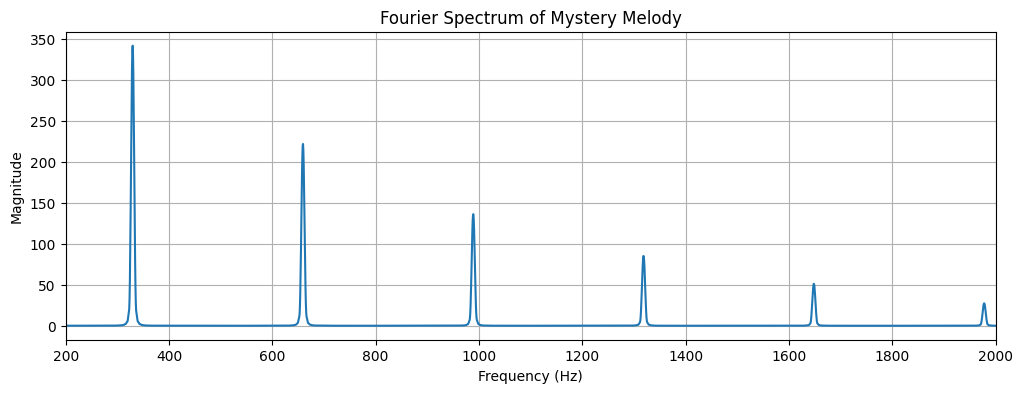

In [8]:
# 2. Compute Fourier spectrum of an isolated window to identify the instrument

start_time = 0.1
end_time = 0.4
segment = audio_data[int(start_time * sample_rate) : int(end_time * sample_rate)]
segment = segment * np.hanning(len(segment))
fft_size = 65536
spectrum = np.abs(np.fft.rfft(segment, n=fft_size))
frequencies = np.fft.rfftfreq(fft_size, 1/sample_rate)
valid_indices = np.where((frequencies >= 250) & (frequencies <= 550))[0]
peak_index = valid_indices[np.argmax(spectrum[valid_indices])]
f_0 = frequencies[peak_index]
print("Fundamental Frequency:", round(f_0, 2), "Hz")

plt.figure(figsize=(12, 4))
plt.plot(frequencies, spectrum)
plt.xlim(200, 2000)
plt.title("Fourier Spectrum of Mystery Melody")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid()
plt.show()

Harmonic 1 : 1.0
Harmonic 2 : 0.65
Harmonic 3 : 0.4
Harmonic 4 : 0.25
Harmonic 5 : 0.15
Harmonic 6 : 0.08


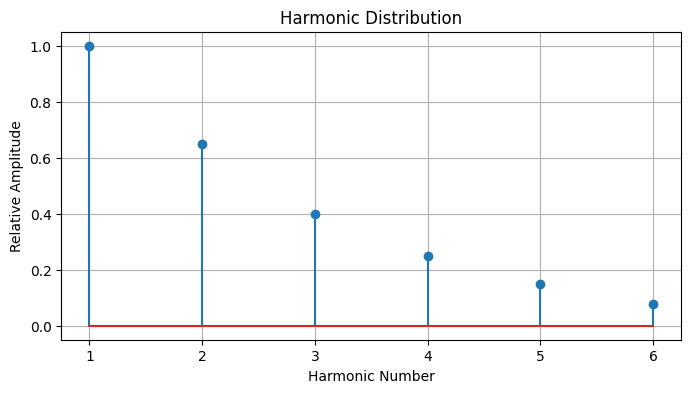

In [10]:
harmonics = []
for n in range(1, 7) :
    target_frequency = n * f_0
    index = np.argmin(np.abs(frequencies - target_frequency))
    amplitude = spectrum[index]
    harmonics.append(amplitude)

harmonics = np.array(harmonics) / harmonics[0]

for n in range(6) :
    print("Harmonic", n+1, ":", round(harmonics[n], 2))

plt.figure(figsize=(8, 4))
plt.stem(range(1, 7), harmonics)
plt.title("Harmonic Distribution")
plt.xlabel("Harmonic Number")
plt.ylabel("Relative Amplitude")
plt.grid()
plt.show()

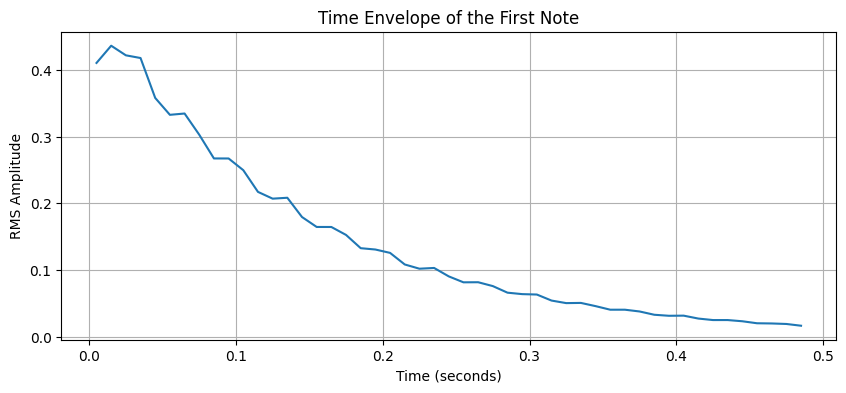

In [9]:
first_note = audio_data[:int(0.5 * sample_rate)]
frame_size = int(0.01 * sample_rate)
rms_values = []
rms_times = []
for start in range(0, len(first_note) - frame_size, frame_size) :
    frame = first_note[start:start + frame_size]
    rms = np.sqrt(np.mean(frame**2))
    rms_values.append(rms)
    rms_times.append((start + frame_size/2) / sample_rate)

plt.figure(figsize=(10, 4))
plt.plot(rms_times, rms_values)
plt.title("Time Envelope of the First Note")
plt.xlabel("Time (seconds)")
plt.ylabel("RMS Amplitude")
plt.grid()
plt.show()

### Instrument Recognition Decision:
Based on the harmonic distribution and envelope, which instrument is performing, and why?

> **Answer:** The instrument is **Piano** because: 1. Both even and odd harmonics are present, 2. The higher harmonics gradually decrease in amplitude, 3. The signal has a fast attack followed by a gradual decay, which is characteristic of a piano. The harmonic distribution also matches the piano model from Section 1.

In [11]:
# 3. Automated pitch detection across the 16 notes (0.5s each)

note_frequencies = {
    "C4": 261.63,
    "D4": 293.66,
    "E4": 329.63,
    "F4": 349.23,
    "G4": 392.00,
    "A4": 440.00,
    "B4": 493.88,
    "C5": 523.25
}

number_of_notes = 16
note_duration = 0.5
detected_notes = []
detected_frequencies = []
for i in range(number_of_notes) :
    start = int(i * note_duration * sample_rate)
    end = int((i + 1) * note_duration * sample_rate)
    segment = audio_data[start + int(0.03 * sample_rate) : end - int(0.03 * sample_rate)]
    segment = segment * np.hanning(len(segment))
    spectrum = np.abs(np.fft.rfft(segment, n=65536))
    frequencies = np.fft.rfftfreq(65536, 1/sample_rate)
    valid_indices = np.where((frequencies >= 250) & (frequencies <= 550))[0]
    peak_index = valid_indices[np.argmax(spectrum[valid_indices])]
    f_0 = frequencies[peak_index]
    closest_note = min(note_frequencies, key=lambda note: abs(note_frequencies[note] - f_0))
    detected_notes.append(closest_note)
    detected_frequencies.append(f_0)
    print("Note", i+1, ":", closest_note, "| Frequency:", round(f_0, 2), "Hz")


Note 1 : E4 | Frequency: 329.73 Hz
Note 2 : E4 | Frequency: 329.73 Hz
Note 3 : F4 | Frequency: 349.24 Hz
Note 4 : G4 | Frequency: 392.31 Hz
Note 5 : G4 | Frequency: 392.31 Hz
Note 6 : F4 | Frequency: 349.24 Hz
Note 7 : E4 | Frequency: 329.73 Hz
Note 8 : D4 | Frequency: 293.39 Hz
Note 9 : C4 | Frequency: 261.76 Hz
Note 10 : C4 | Frequency: 261.76 Hz
Note 11 : D4 | Frequency: 293.39 Hz
Note 12 : E4 | Frequency: 329.73 Hz
Note 13 : D4 | Frequency: 293.39 Hz
Note 14 : D4 | Frequency: 293.39 Hz
Note 15 : C4 | Frequency: 261.76 Hz
Note 16 : C4 | Frequency: 261.76 Hz


### Melody Recognition Results:
- **Sequence of 16 detected notes:**
- **Identified musical piece / composer:**

> **Answer:**

> Sequence of 16 detected notes: E4, E4, F4, G4, G4, F4, E4, D4, C4, C4, D4, E4, D4, D4, C4, C4

> Identified musical piece / composer: Ode to Joy by Beethoven (Symphony No. 9)

---
## Section 3: Periodic Noise Removal with Fourier Series & Spectrogram Visualization

The audio recording `audio_assets/noisy_music.wav` was corrupted during recording by high-frequency periodic interference (a persistent whistle tone):
$$s_{\text{noisy}}(t) = s_{\text{clean}}(t) + A_{\text{noise}} \sin(2\pi f_{\text{noise}} t)$$

Your task is to detect the exact noise frequency, filter it out using Fourier Series projection, and visualize the result with spectrograms.

Sample Rate: 44100
Duration: 4.2
Number of Samples: 185220


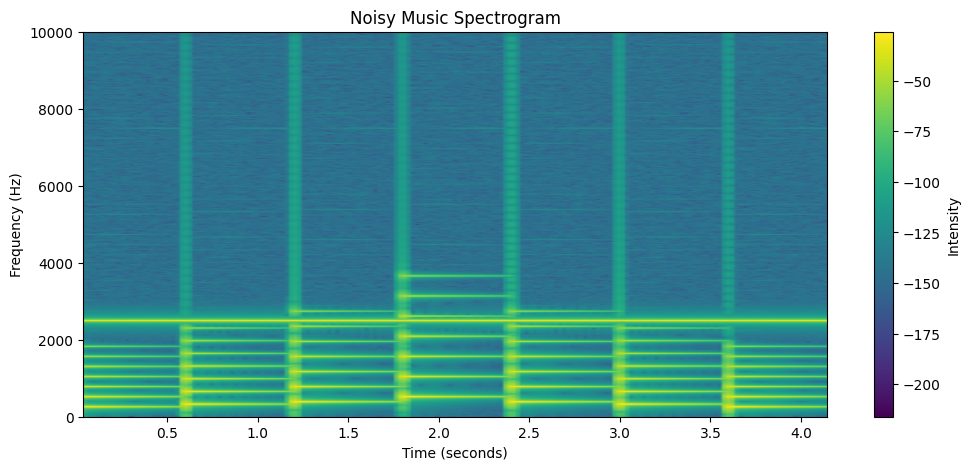

In [12]:
# 1. Load noisy_music.wav and plot its initial spectrogram

with wave.open("audio_assets/noisy_music.wav", "rb") as file :
    sample_rate = file.getframerate()
    frames = file.getnframes()
    audio = file.readframes(frames)

audio = np.frombuffer(audio, dtype=np.int16)
audio = audio / 32768
time = np.arange(len(audio)) / sample_rate
print("Sample Rate:", sample_rate)
print("Duration:", len(audio) / sample_rate)
print("Number of Samples:", len(audio))
plt.figure(figsize=(12, 5))
plt.specgram(audio, NFFT=4096, Fs=sample_rate, noverlap=3072)
plt.ylim(0, 10000)
plt.title("Noisy Music Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Intensity")
plt.show()

In [14]:
# 2. Estimate and cancel periodic noise using Fourier series, then export denoised audio

spectrum = np.abs(np.fft.rfft(audio))
frequencies = np.fft.rfftfreq(len(audio), 1/sample_rate)
valid_indices = np.where((frequencies >= 2000) & (frequencies <= 10000))[0]
peak_index = valid_indices[np.argmax(spectrum[valid_indices])]
f_noise = frequencies[peak_index]
print("Noise Frequency:", f_noise, "Hz")
N = len(audio)
T = N / sample_rate
a_noise = (2 / N) * np.sum(audio * np.cos(2 * np.pi * f_noise * time))
b_noise = (2 / N) * np.sum(audio * np.sin(2 * np.pi * f_noise * time))
print("a_noise:", a_noise)
print("b_noise:", b_noise)
noise = (a_noise * np.cos(2 * np.pi * f_noise * time) + b_noise * np.sin(2 * np.pi * f_noise * time))
clean_audio = audio - noise
print("Noise removed")
clean_audio = np.clip(clean_audio, -1, 1)
output_audio = (clean_audio * 32767).astype(np.int16)
with wave.open("denoised_output.wav", "wb") as file :
    file.setnchannels(1)
    file.setsampwidth(2)
    file.setframerate(sample_rate)
    file.writeframes(output_audio.tobytes())
print("denoised_output.wav saved")

Noise Frequency: 2500.0 Hz
a_noise: 4.127017641315812e-06
b_noise: 0.17916951465401132
Noise removed
denoised_output.wav saved


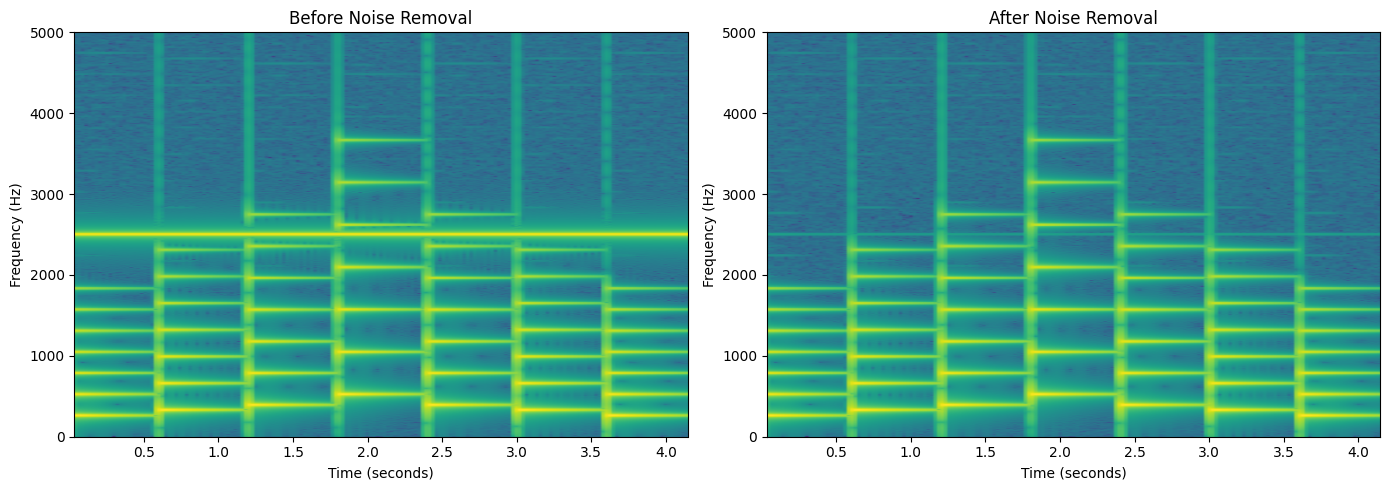

In [15]:
# 3. Compare spectrograms before and after filtering

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.specgram(audio, NFFT=4096, Fs=sample_rate, noverlap=3072, scale='dB')
plt.ylim(0, 5000)
plt.title("Before Noise Removal")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.subplot(1, 2, 2)
plt.specgram(clean_audio, NFFT=4096, Fs=sample_rate, noverlap=3072, scale='dB')
plt.ylim(0, 5000)
plt.title("After Noise Removal")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

### Discussion & Analysis for Section 3:
- What was the exact frequency of the corrupting whistle tone?
- What is the key advantage of selective Fourier Series harmonic removal compared to standard low-pass filtering?

> **Answer:**

> **1. Noise Frequency:** The exact frequency of the interfering whistle tone is **2500 Hz**, detected using the Fourier Transform.

> **2. Advantage of Fourier Series Removal:** Selective Fourier Series removal eliminates only the unwanted noise frequency while preserving the other frequency components of the music. In contrast, a low-pass filter removes all frequencies above a certain cutoff frequency, which may also remove important musical harmonics and reduce sound quality. Therefore, Fourier Series removal provides more precise noise reduction while preserving the original music.

---
## Optional Bonus Section: Piano Song Synthesis with Fourier Series

Synthesize a musical piece (such as Beethoven's *Für Elise* or your favorite melody) using the Piano Fourier model and export it to `my_piano_song.wav`.

# Piano Notes (Valse, Evgeny Grinko)

- Time signature: 3/4 (waltz) — about 191 BPM (one beat ≈ 0.31 s, one bar ≈ 0.94 s)
- Key: F# minor (C# major chord as the dominant)
- Left-hand pattern: bass note on beat 1, chord on beats 2 and 3 ("oom-pah-pah")

## Chord progression (19 bars)

| Bars | Chord | Notes |
|------|-------|-------|
| 1–6   | F# minor | F#–A–C# (bass F#) |
| 7–10  | D major  | D–F#–A (bass D) |
| 11–12 | B minor  | B–D–F# (bass B) |
| 13–19 | C# major | C#–E#(F)–G# (bass C#) |

## Approximate melody (right hand, per beat; octave 5)

| Bar | Beat 1 | Beat 2 | Beat 3 |
|-----|--------|--------|--------|
| 1 | F#5 | F#5 | G#5 |
| 2 | E5 | C#5 | C#5 |
| 3 | D5 | C#5 | C#5 |
| 4 | C#5 | C#5 | C#5 |
| 5 | C#5 | C#5 | G#5 |
| 6 | E5 | C#5 | C#5 |
| 7 | D5 | D5 | D5 |
| 8 | D5 | F#5 | F#5 |
| 9 | D5 | C#5 | D5 |
| 10 | C#5 | C#5 | C#5 |
| 11 | C#5 | C#5 | C#5 |
| 12 | C#5 | C#5 | D5 |
| 13 | C#5 | C#5 | D5 |
| 14 | C#5 | C#5 | C#5 |
| 15 | G#5 | C#5 | F5 |
| 16 | G#5 | G#5 | G#5 |
| 17 | G#5 | C#5 | D5 |
| 18 | C#5 | C#5 | C#5 |
| 19 | G#5 | – | – |


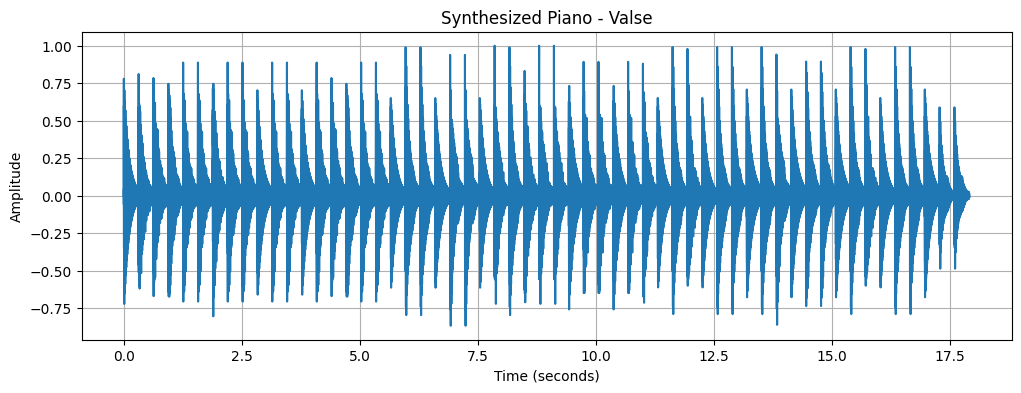

my_piano_song.wav created


In [17]:
# Optional Bonus: Synthesize a melody of your choice using your piano Fourier model

sample_rate = 44100
bpm = 191
beat_duration = 60 / bpm
duration = beat_duration
volume = 0.25

notes = {
    "F#2": 92.50, "B2": 123.47, "D3": 146.83,
    "C#3": 138.59, "G#4": 415.30,
    "F#3": 185.00, "A3": 220.00, "C#4": 277.18,
    "D4": 293.66, "F#4": 369.99, "A4": 440.00,
    "C#5": 554.37, "D5": 587.33, "E5": 659.25,
    "F5": 698.46, "F#5": 739.99, "G#5": 830.61
}

def piano_note(frequency, duration) :
    t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)
    amplitudes = [1.0, 0.65, 0.40, 0.25, 0.15, 0.08, 0.04]
    sound = np.zeros(len(t))
    for n in range(1, 8) :
        sound += amplitudes[n-1] * np.sin(2 * np.pi * n * frequency * t)

    envelope = np.exp(-3 * t / duration)
    return sound * envelope

melody = [
    ["F#5", "F#5", "G#5"],
    ["E5", "C#5", "C#5"],
    ["D5", "C#5", "C#5"],
    ["C#5", "C#5", "C#5"],
    ["C#5", "C#5", "G#5"],
    ["E5", "C#5", "C#5"],
    ["D5", "D5", "D5"],
    ["D5", "F#5", "F#5"],
    ["D5", "C#5", "D5"],
    ["C#5", "C#5", "C#5"],
    ["C#5", "C#5", "C#5"],
    ["C#5", "C#5", "D5"],
    ["C#5", "C#5", "D5"],
    ["C#5", "C#5", "C#5"],
    ["G#5", "C#5", "F5"],
    ["G#5", "G#5", "G#5"],
    ["G#5", "C#5", "D5"],
    ["C#5", "C#5", "C#5"],
    ["G#5", None, None]
]

progression = (
    [["F#2", ["F#3", "A3", "C#4"]]] * 6 +
    [["D3", ["D4", "F#4", "A4"]]] * 4 +
    [["B2", ["B2", "D4", "F#4"]]] * 2 +
    [["C#3", ["C#4", "F4", "G#4"]]] * 7
)

notes["B2"] = 123.47
notes["F4"] = 349.23

right_hand = np.zeros(int(19 * 3 * beat_duration * sample_rate))
left_hand = np.zeros_like(right_hand)

for bar_index, bar in enumerate(melody) :
    for beat_index, note in enumerate(bar) :
        if note is not None:
            start = int((bar_index * 3 + beat_index) * beat_duration * sample_rate)
            sound = piano_note(notes[note], beat_duration)

            end = min(start + len(sound), len(right_hand))
            right_hand[start:end] += sound[:end-start]

for bar_index, (bass, chord) in enumerate(progression) :
    start = int(bar_index * 3 * beat_duration * sample_rate)
    sound = piano_note(notes[bass], beat_duration)
    end = min(start + len(sound), len(left_hand))
    left_hand[start:end] += sound[:end-start]
    for beat_index in [1, 2] :
        start = int((bar_index * 3 + beat_index) * beat_duration * sample_rate)
        for note in chord :
            sound = piano_note(notes[note], beat_duration) * 0.45
            end = min(start + len(sound), len(left_hand))
            left_hand[start:end] += sound[:end-start]

song = volume * (right_hand + left_hand)
song = song / np.max(np.abs(song))
audio = (song * 32767).astype(np.int16)

with wave.open("my_piano_song.wav", "wb") as file :
    file.setnchannels(1)
    file.setsampwidth(2)
    file.setframerate(sample_rate)
    file.writeframes(audio.tobytes())

time = np.arange(len(song)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(time, song)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Synthesized Piano - Valse")
plt.grid()
plt.show()

print("my_piano_song.wav created")

In this section, I synthesized a short segment of **Valse by Evgeny Grinko** using a simplified Piano Fourier Model.

First, I obtained an approximate sequence of musical notes and chords from the selected segment. The melody was assigned to the right hand, while the left hand played the bass notes and chords in a 3/4 waltz pattern.

Each musical note was converted into its corresponding fundamental frequency. Then, the piano sound was generated using a Fourier Series model:

$
s(t)=\sum_{n=1}^{7} A_n\sin(2\pi nft)
$

where $f$ is the fundamental frequency and $A_n$ represents the amplitude of each harmonic.

Seven harmonics with decreasing amplitudes were used to create a simplified piano-like timbre. An exponential decay envelope was also applied to simulate the natural fading of piano notes.

Finally, the synthesized melody and accompaniment were combined to create the complete audio signal and exported as **`my_piano_song.wav`**.

### Result

The generated audio successfully reproduced an approximate version of the selected Valse segment using synthesized piano sounds. This experiment demonstrates how Fourier Series can be used to construct musical sounds from individual frequencies and their harmonics.